# T11: ranker v0
Regenerates every README figure from `data/` (written by `analysis.py --compute` from `runs/t11_ranker`). No heavy computation here.

In [1]:
import os, sys, json, pandas as pd
from IPython.display import Image, display
sys.path.insert(0, os.getcwd())
import analysis
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
analysis.figures()
hm = json.load(open('data/headline_model.json')); {k: hm[k] for k in ('head_key','objective','thresholds','hand_train','n_rounds')}

{'head_key': 'n1000_base_ndcg',
 'objective': 'ndcg',
 'thresholds': {'no_decline': -inf,
  'match_hand_precision': 1.3571535348892212,
  'match_hand_coverage': 1.8719358444213867,
  'precision_0.80': 1.0061999559402466},
 'hand_train': {'coverage': 0.2, 'precision': 0.89, 'success': 0.178},
 'n_rounds': 150}

## Hand arbitration vs ranker vs oracle, per period bin
Stacked bars: success / alias / wrong / declined. Oracle = best candidate in the list (hatched).

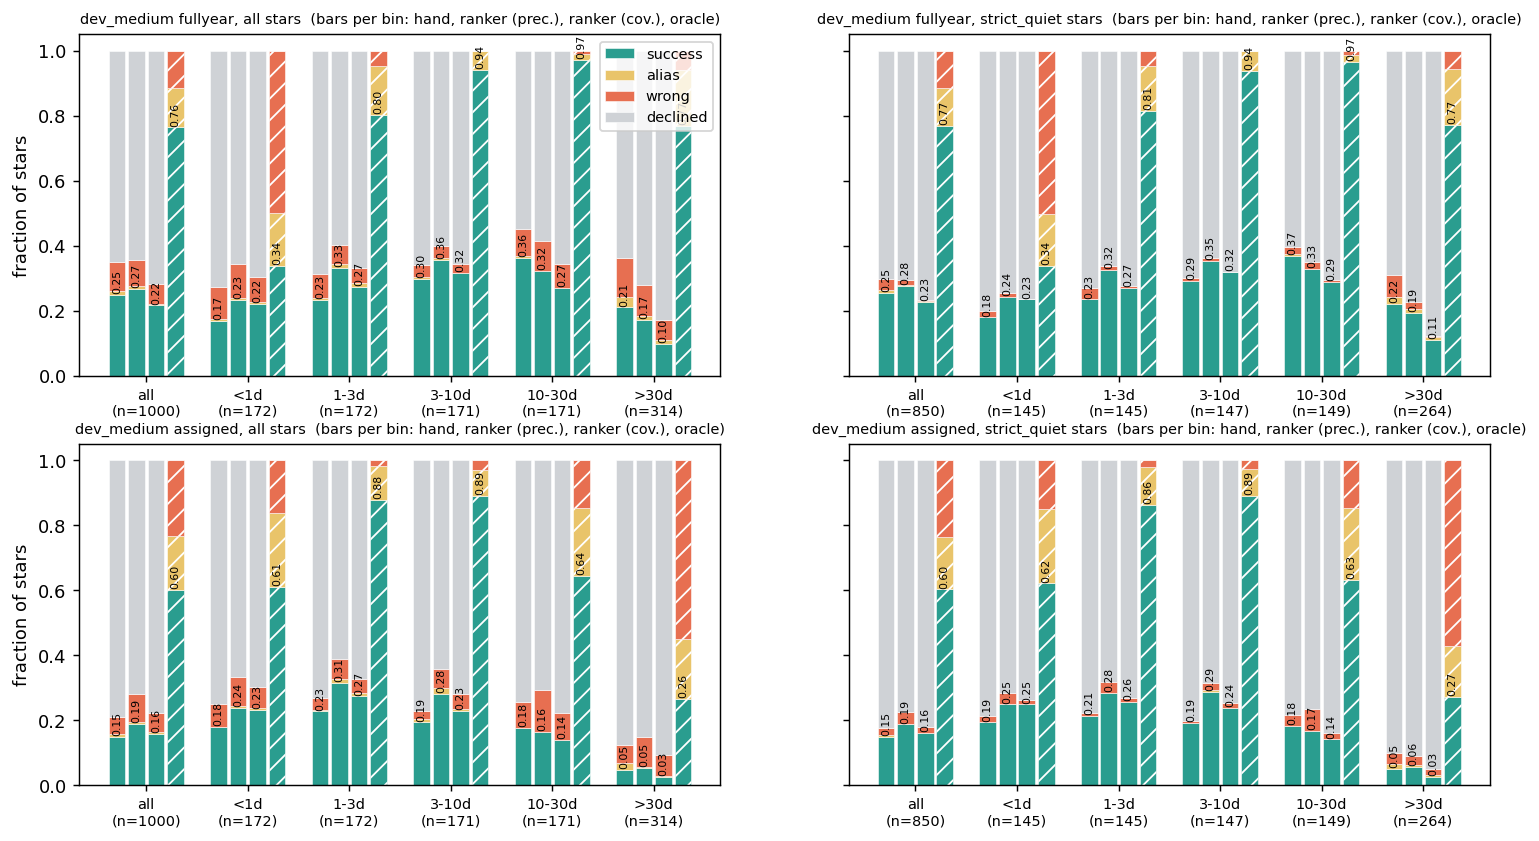

alias  declined  success  wrong
dev      subset                  method                                                      
assigned all                     hand arbitration             0.009     0.789    0.148  0.054
                                 oracle (best in list)        0.165     0.000    0.601  0.234
                                 ranker match_hand_coverage   0.005     0.777    0.158  0.060
                                 ranker match_hand_precision  0.007     0.718    0.188  0.087
                                 ranker no_decline            0.087     0.000    0.328  0.585
                                 ranker precision_0.80        0.012     0.662    0.218  0.108
         searchable              hand arbitration             0.012     0.724    0.218  0.047
                                 oracle (best in list)        0.124     0.000    0.813  0.063
                                 ranker match_hand_coverage   0.007     0.707    0.232  0.053
                                 ranker match_hand_precision  0.010     0.640    0.276  0.074
                                 ranker no_decline            0.101     0.000    0.456  0.443
                                 ranker precision_0.80        0.015     0.578    0.318  0.090
         strict_quiet            hand arbitration             0.005     0.824    0.149  0.022
                                 oracle (best in list)        0.160     0.000    0.602  0.238
                                 ranker match_hand_coverage   0.001     0.822    0.160  0.016
                                 ranker match_hand_precision  0.002     0.774    0.187  0.036
                                 ranker no_decline            0.089     0.000    0.345  0.566
                                 ranker precision_0.80        0.007     0.721    0.221  0.051
         strict_quiet_searchable hand arbitration             0.007     0.762    0.217  0.014
                                 oracle (best in list)        0.123     0.000    0.815  0.062
                                 ranker match_hand_coverage   0.002     0.754    0.232  0.012
                                 ranker match_hand_precision  0.003     0.696    0.272  0.029
                                 ranker no_decline            0.101     0.000    0.474  0.426
                                 ranker precision_0.80        0.007     0.631    0.320  0.043
fullyear all                     hand arbitration             0.014     0.650    0.248  0.088
                                 oracle (best in list)        0.121     0.000    0.764  0.115
                                 ranker match_hand_coverage   0.006     0.719    0.216  0.059
                                 ranker match_hand_precision  0.008     0.645    0.267  0.080
                                 ranker no_decline            0.058     0.000    0.441  0.501
                                 ranker precision_0.80        0.008     0.589    0.306  0.097
         searchable              hand arbitration             0.014     0.642    0.268  0.076
                                 oracle (best in list)        0.105     0.000    0.787  0.108
                                 ranker match_hand_coverage   0.006     0.702    0.234  0.057
                                 ranker match_hand_precision  0.009     0.624    0.289  0.078
                                 ranker no_decline            0.057     0.000    0.473  0.470
                                 ranker precision_0.80        0.009     0.570    0.331  0.090
         strict_quiet            hand arbitration             0.008     0.702    0.254  0.035
                                 oracle (best in list)        0.118     0.000    0.768  0.114
                                 ranker match_hand_coverage   0.002     0.768    0.226  0.004
                                 ranker match_hand_precision  0.004     0.705    0.275  0.016
                                 ranker no_decline            0.058     0.000    0.467  0.475
                    

In [2]:
display(Image('figures/fig_comparison_by_bin.png'))
c = pd.read_csv('data/comparison.csv')
c[c.bin=='all'].pivot_table(index=['dev','subset','method'], values=['success','alias','wrong','declined']).round(3)

Overall coverage / precision (success among answered) per operating point; paired win counts with a sign test.

In [3]:
t = c[(c.bin=='all') & c.subset.isin(['all','strict_quiet'])].copy()
t['coverage'] = 1 - t.declined; t['precision'] = t.success / t.coverage
display(t[['dev','subset','method','coverage','success','wrong','precision']].round(3))
from scipy.stats import binomtest
fm = pd.read_csv('data/per_star_dev.csv.gz')
for d, g in fm.groupby('dev'):
    h, r = (g.case=='hand wins').sum(), (g.case=='ranker wins').sum()
    print(d, 'hand wins', h, 'ranker wins', r, 'sign-test p =', round(binomtest(int(r), int(h+r)).pvalue, 4))

,dev,subset,method,coverage,success,wrong,precision
0,fullyear,all,hand arbitration,0.350,0.248,0.088,0.709
6,fullyear,all,oracle (best in list),1.000,0.764,0.115,0.764
12,fullyear,all,ranker no_decline,1.000,0.441,0.501,0.441
18,fullyear,all,ranker match_hand_precision,0.355,0.267,0.080,0.752
24,fullyear,all,ranker match_hand_coverage,0.281,0.216,0.059,0.769
30,fullyear,all,ranker precision_0.80,0.411,0.306,0.097,0.745
36,fullyear,strict_quiet,hand arbitration,0.298,0.254,0.035,0.854
42,fullyear,strict_quiet,oracle (best in list),1.000,0.768,0.114,0.768
48,fullyear,strict_quiet,ranker no_decline,1.000,0.467,0.475,0.467
54,fullyear,strict_quiet,ranker match_hand_precision,0.295,0.275,0.016,0.932


assigned hand wins 12 ranker wins 52 sign-test p = 0.0
fullyear hand wins 39 ranker wins 58 sign-test p = 0.0671


## Coverage vs accuracy
Thresholds are calibrated on the training OOF curve (grey) and applied unchanged to dev.

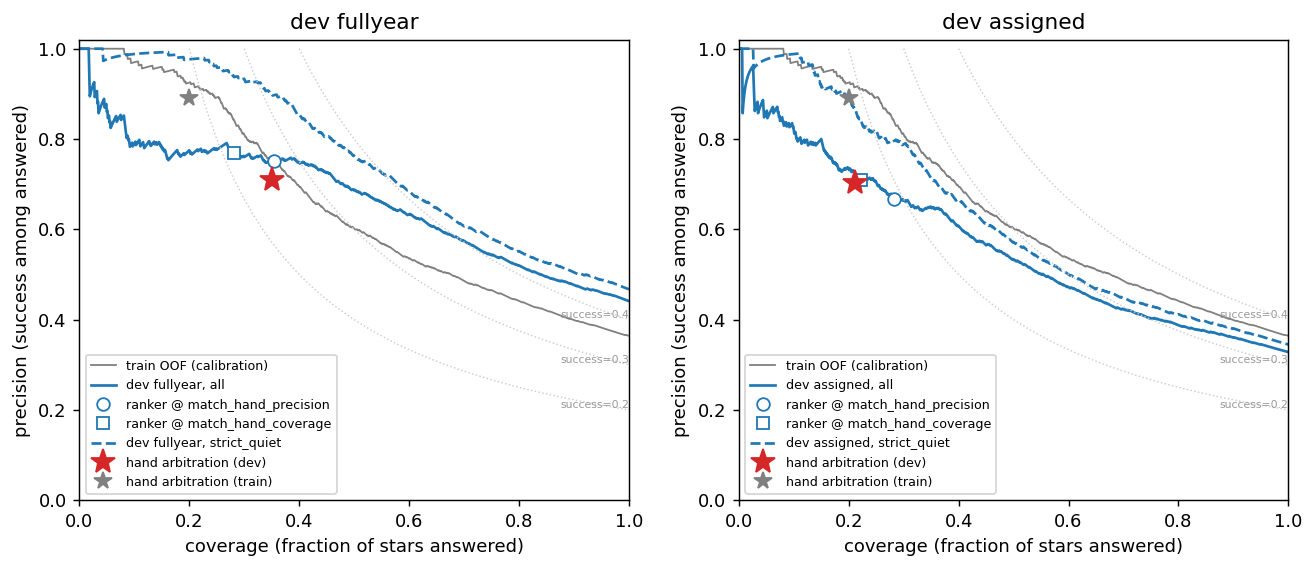

In [4]:
display(Image('figures/fig_coverage_accuracy.png'))

## Learning curve

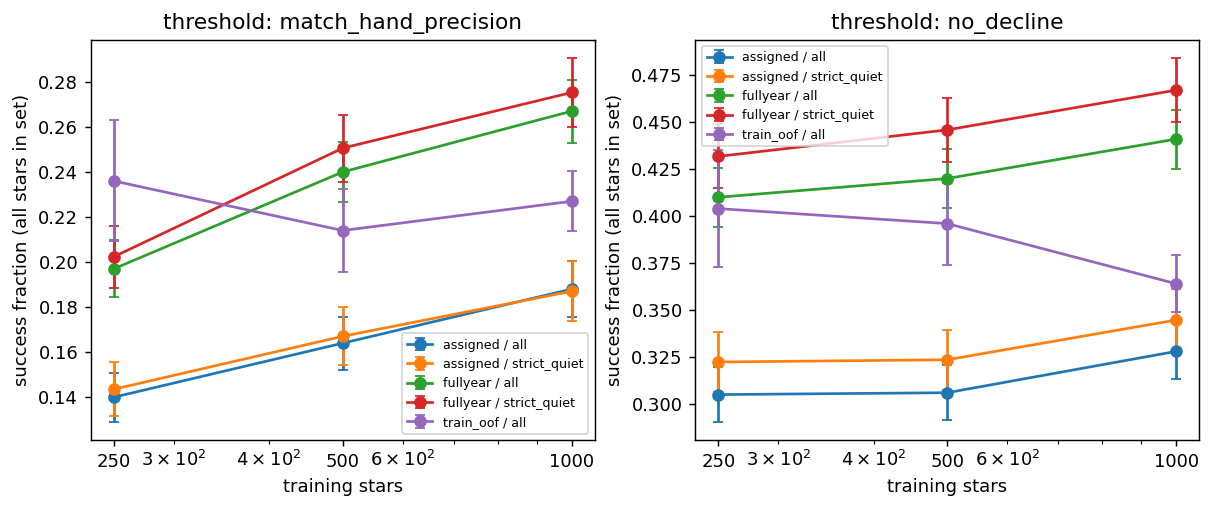

dev                           assigned                                                        fullyear                                                       train_oof           
subset                             all                    strict_quiet                             all                    strict_quiet                             all           
threshold         match_hand_precision no_decline match_hand_precision no_decline match_hand_precision no_decline match_hand_precision no_decline match_hand_precision no_decline
objective n_train                                                                                                                                                                
ndcg      250                    0.140      0.305                0.144      0.322                0.197      0.410                0.202      0.432                0.236      0.404
          500                    0.164      0.306                0.167      0.324                0.240      0.420                0.251      0.446                0.214      0.396
          1000                   0.188      0.328                0.187      0.345                0.267      0.441                0.275      0.467                0.227      0.364
pairwise  1000                   0.187      0.326                0.189      0.346                0.266      0.438                0.276      0.465                0.218      0.363

In [5]:
display(Image('figures/fig_learning_curve.png'))
r = pd.read_csv('data/runs_overall.csv')
r[(r.variant=='base')].pivot_table(index=['objective','n_train'], columns=['dev','subset','threshold'], values='success').round(3)

## Ablations (label variants) and objective

In [6]:
r[(r.n_train==r.n_train.max())&(r.subset=='all')].pivot_table(index=['variant','objective'], columns=['dev','threshold'], values=['success','declined']).round(3)

declined                                                                                         success                                             \
dev                                 assigned                        fullyear                       train_oof                        assigned                        fullyear              
threshold               match_hand_precision no_decline match_hand_precision no_decline match_hand_precision no_decline match_hand_precision no_decline match_hand_precision no_decline   
variant       objective                                                                                                                                                                   
base          ndcg                     0.718        0.0                0.645        0.0                0.745        0.0                0.188      0.328                0.267      0.441   
              pairwise                 0.727        0.0                0.656        0.0                0.756        0.0                0.187      0.326                0.266      0.438   
fiterr0       ndcg                     0.747        0.0                0.664        0.0                0.768        0.0                0.180      0.326                0.255      0.444   
wideband_rel0 ndcg                     0.756        0.0                0.688        0.0                0.779        0.0                0.171      0.327                0.240      0.447   
wideband_w05  ndcg                     0.736        0.0                0.661        0.0                0.768        0.0                0.182      0.331                0.256      0.446   

                                                         
dev                                train_oof             
threshold               match_hand_precision no_decline  
variant       objective                                  
base          ndcg                     0.227      0.364  
              pairwise                 0.218      0.363  
fiterr0       ndcg                     0.207      0.362  
wideband_rel0 ndcg                     0.197      0.358  
wideband_w05  ndcg                     0.207      0.361

In [7]:
# threshold-free: success when every model answers hand arbitration's dev coverage (a reading, not used for selection)
pd.read_csv('data/fixed_coverage.csv').round(3).sort_values(['dev','n_train','variant'])

,key,n_train,variant,objective,dev,coverage,success,precision
9,n250_base_ndcg,250,base,ndcg,assigned,0.211,0.153,0.725
7,n500_base_ndcg,500,base,ndcg,assigned,0.211,0.158,0.749
3,n1000_base_ndcg,1000,base,ndcg,assigned,0.211,0.153,0.725
11,n1000_base_pairwise,1000,base,pairwise,assigned,0.211,0.154,0.730
5,n1000_fiterr0_ndcg,1000,fiterr0,ndcg,assigned,0.211,0.155,0.735
13,n1000_wideband_rel0_ndcg,1000,wideband_rel0,ndcg,assigned,0.211,0.154,0.730
1,n1000_wideband_w05_ndcg,1000,wideband_w05,ndcg,assigned,0.211,0.154,0.730
8,n250_base_ndcg,250,base,ndcg,fullyear,0.350,0.257,0.734
6,n500_base_ndcg,500,base,ndcg,fullyear,0.350,0.263,0.751
2,n1000_base_ndcg,1000,base,ndcg,fullyear,0.350,0.263,0.751


In [8]:
pd.read_csv('data/ablation_detail.csv').round(3)

,key,variant,objective,dev,stars,n,success,correct,diffrot,declined,top1_success_no_decline,top_is_fit_error,answered_fit_error
0,n1000_wideband_w05_ndcg,wideband_w05,ndcg,fullyear,all,1000,0.256,0.200,0.056,0.661,0.446,0.005,0.0
1,n1000_wideband_w05_ndcg,wideband_w05,ndcg,fullyear,ge_0p5,72,0.111,0.014,0.097,0.847,0.403,0.000,0.0
2,n1000_wideband_w05_ndcg,wideband_w05,ndcg,fullyear,not_ge_0p5,928,0.267,0.214,0.053,0.647,0.449,0.005,0.0
3,n1000_wideband_w05_ndcg,wideband_w05,ndcg,assigned,all,1000,0.182,0.131,0.051,0.736,0.331,0.018,0.0
4,n1000_wideband_w05_ndcg,wideband_w05,ndcg,assigned,ge_0p5,72,0.139,0.056,0.083,0.806,0.306,0.000,0.0
5,n1000_wideband_w05_ndcg,wideband_w05,ndcg,assigned,not_ge_0p5,928,0.185,0.137,0.048,0.731,0.333,0.019,0.0
6,n1000_base_ndcg,base,ndcg,fullyear,all,1000,0.267,0.207,0.060,0.645,0.441,0.004,0.0
7,n1000_base_ndcg,base,ndcg,fullyear,ge_0p5,72,0.125,0.014,0.111,0.819,0.389,0.000,0.0
8,n1000_base_ndcg,base,ndcg,fullyear,not_ge_0p5,928,0.278,0.222,0.056,0.631,0.445,0.004,0.0
9,n1000_base_ndcg,base,ndcg,assigned,all,1000,0.188,0.137,0.051,0.718,0.328,0.017,0.0


## Feature importance

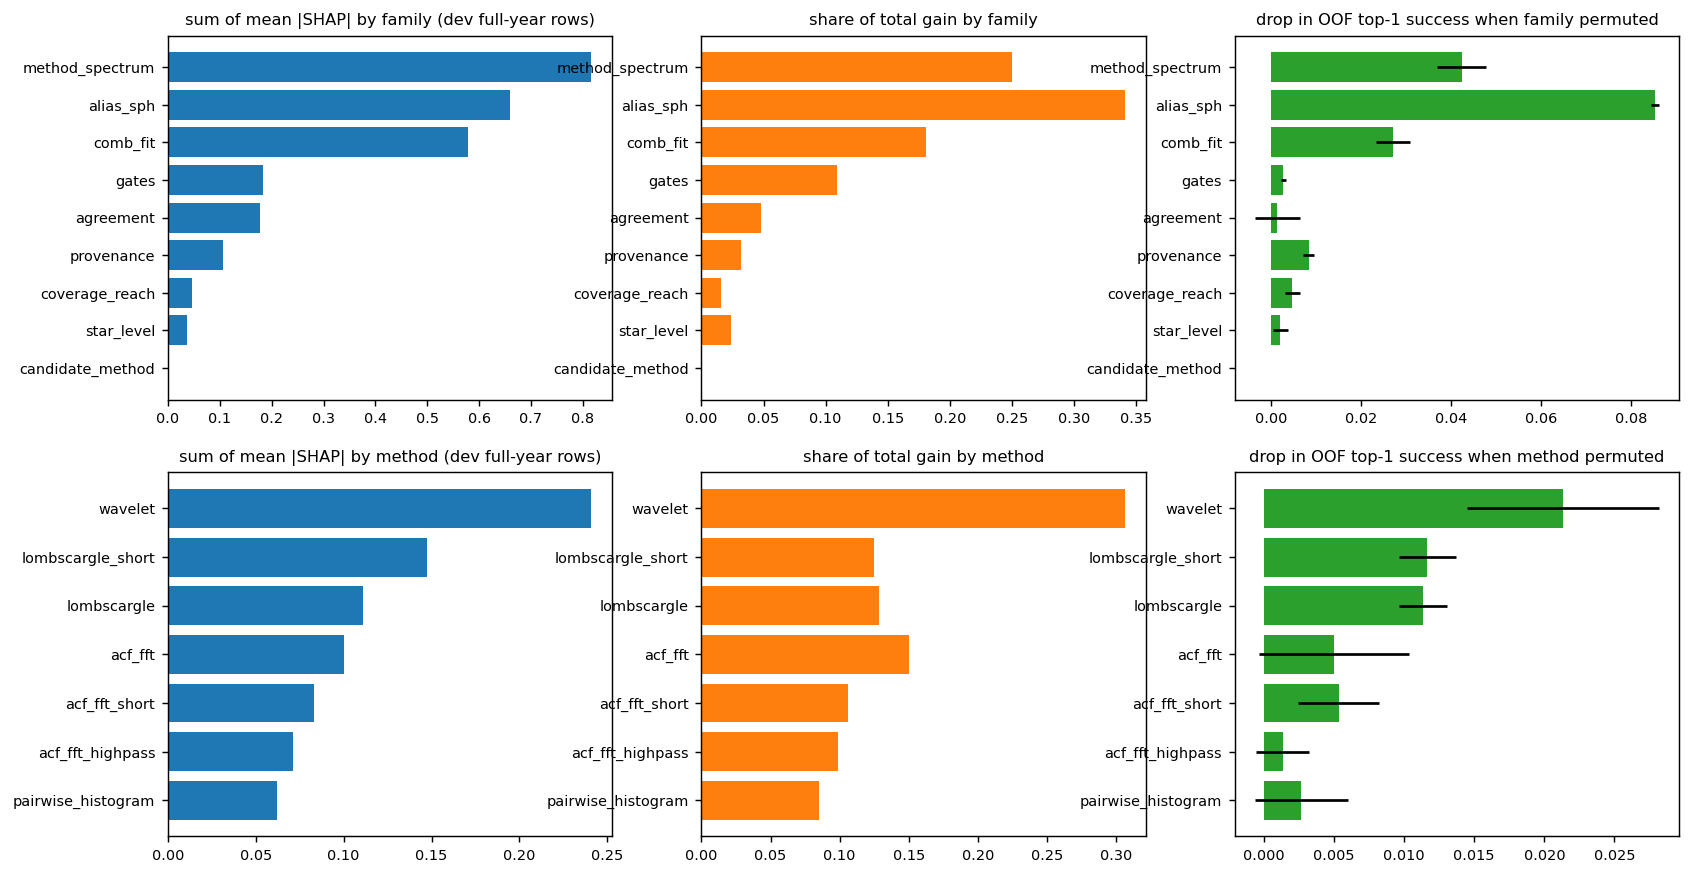

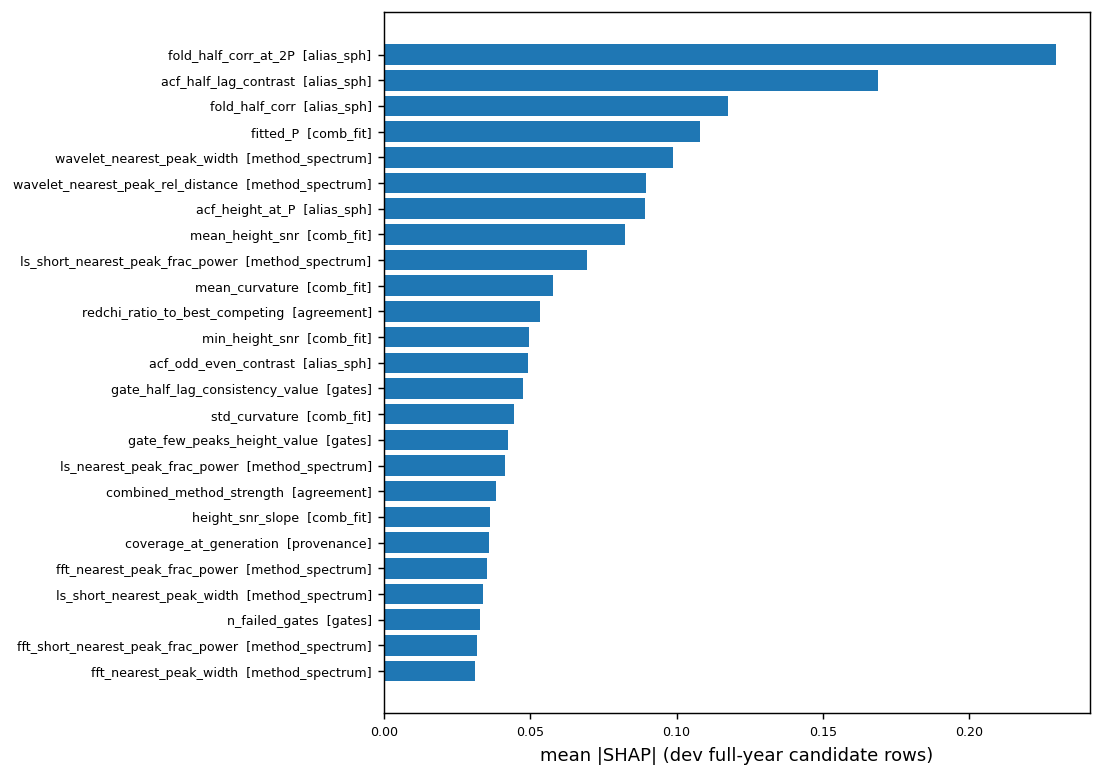

,group,n_features,drop_mean,drop_std,ref_oof_top1_success
5,family:alias_sph,6,0.0853,0.0009,0.364
6,family:method_spectrum,34,0.0423,0.0054,0.364
1,family:comb_fit,31,0.0270,0.0037,0.364
15,method:wavelet,5,0.0213,0.0068,0.364
12,method:lombscargle_short,5,0.0117,0.0021,0.364
10,method:lombscargle,6,0.0113,0.0017,0.364
0,family:provenance,8,0.0083,0.0012,0.364
13,method:acf_fft_short,5,0.0053,0.0029,0.364
9,method:acf_fft,6,0.0050,0.0054,0.364
4,family:coverage_reach,13,0.0047,0.0017,0.364


In [9]:
display(Image('figures/fig_importance.png'))
display(Image('figures/fig_top_features.png'))
pd.read_csv('data/perm_importance.csv').sort_values('drop_mean', ascending=False).round(4)

In [10]:
pd.read_csv('data/family_correlation.csv')

,family,n_features,n_pairs_rho_gt_0p95,examples
0,provenance,8,1,period~log_period (1.00)
1,comb_fit,31,3,redchi~log_redchi (1.00); n_peaks_dropped~n_pe...
2,candidate_method,3,0,NaN
3,gates,22,2,passes_min_peaks~gate_n_peaks_pass (1.00); gat...
4,coverage_reach,13,6,baseline_days~n_acf_points (1.00); baseline_da...
5,alias_sph,6,0,NaN
6,method_spectrum,34,1,fft_nearest_peak_snr~fft_short_nearest_peak_sn...
7,agreement,10,1,redchi_ratio_to_best_competing~redchi_ratio_to...
8,star_level,10,5,r_var~flicker_std (0.99); von_neumann_eta~flip...


## Failure modes

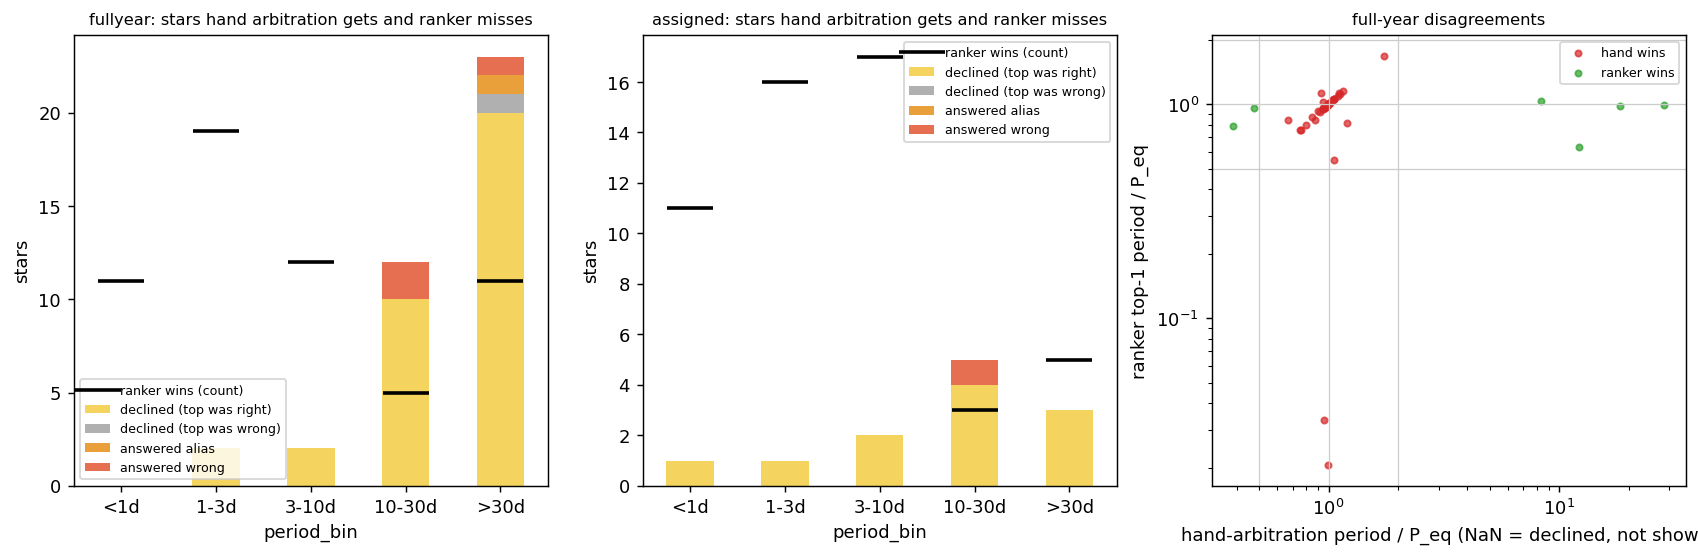

why                 answered alias  answered wrong  declined (top was right)  declined (top was wrong)
dev      case                                                                                         
assigned hand wins               0               1                        11                         0
         neither                 7              86                       129                       578
fullyear hand wins               1               3                        34                         1
         neither                 7              77                       140                       470

In [11]:
display(Image('figures/fig_failure_modes.png'))
fm = pd.read_csv('data/per_star_dev.csv.gz')
pd.crosstab([fm.dev, fm.case], fm.why)

In [12]:
pd.read_csv('data/top_kind.csv').round(3)

,dev,top_kind,n,answered,top_success,success_if_answered
0,assigned,beyond_reach,88.0,0.023,0.193,0.000
1,assigned,fit_error,17.0,0.000,0.118,NaN
2,assigned,fitted,895.0,0.313,0.345,0.671
3,fullyear,beyond_reach,15.0,0.000,0.267,NaN
4,fullyear,fit_error,4.0,0.000,0.500,NaN
5,fullyear,fitted,981.0,0.362,0.443,0.752


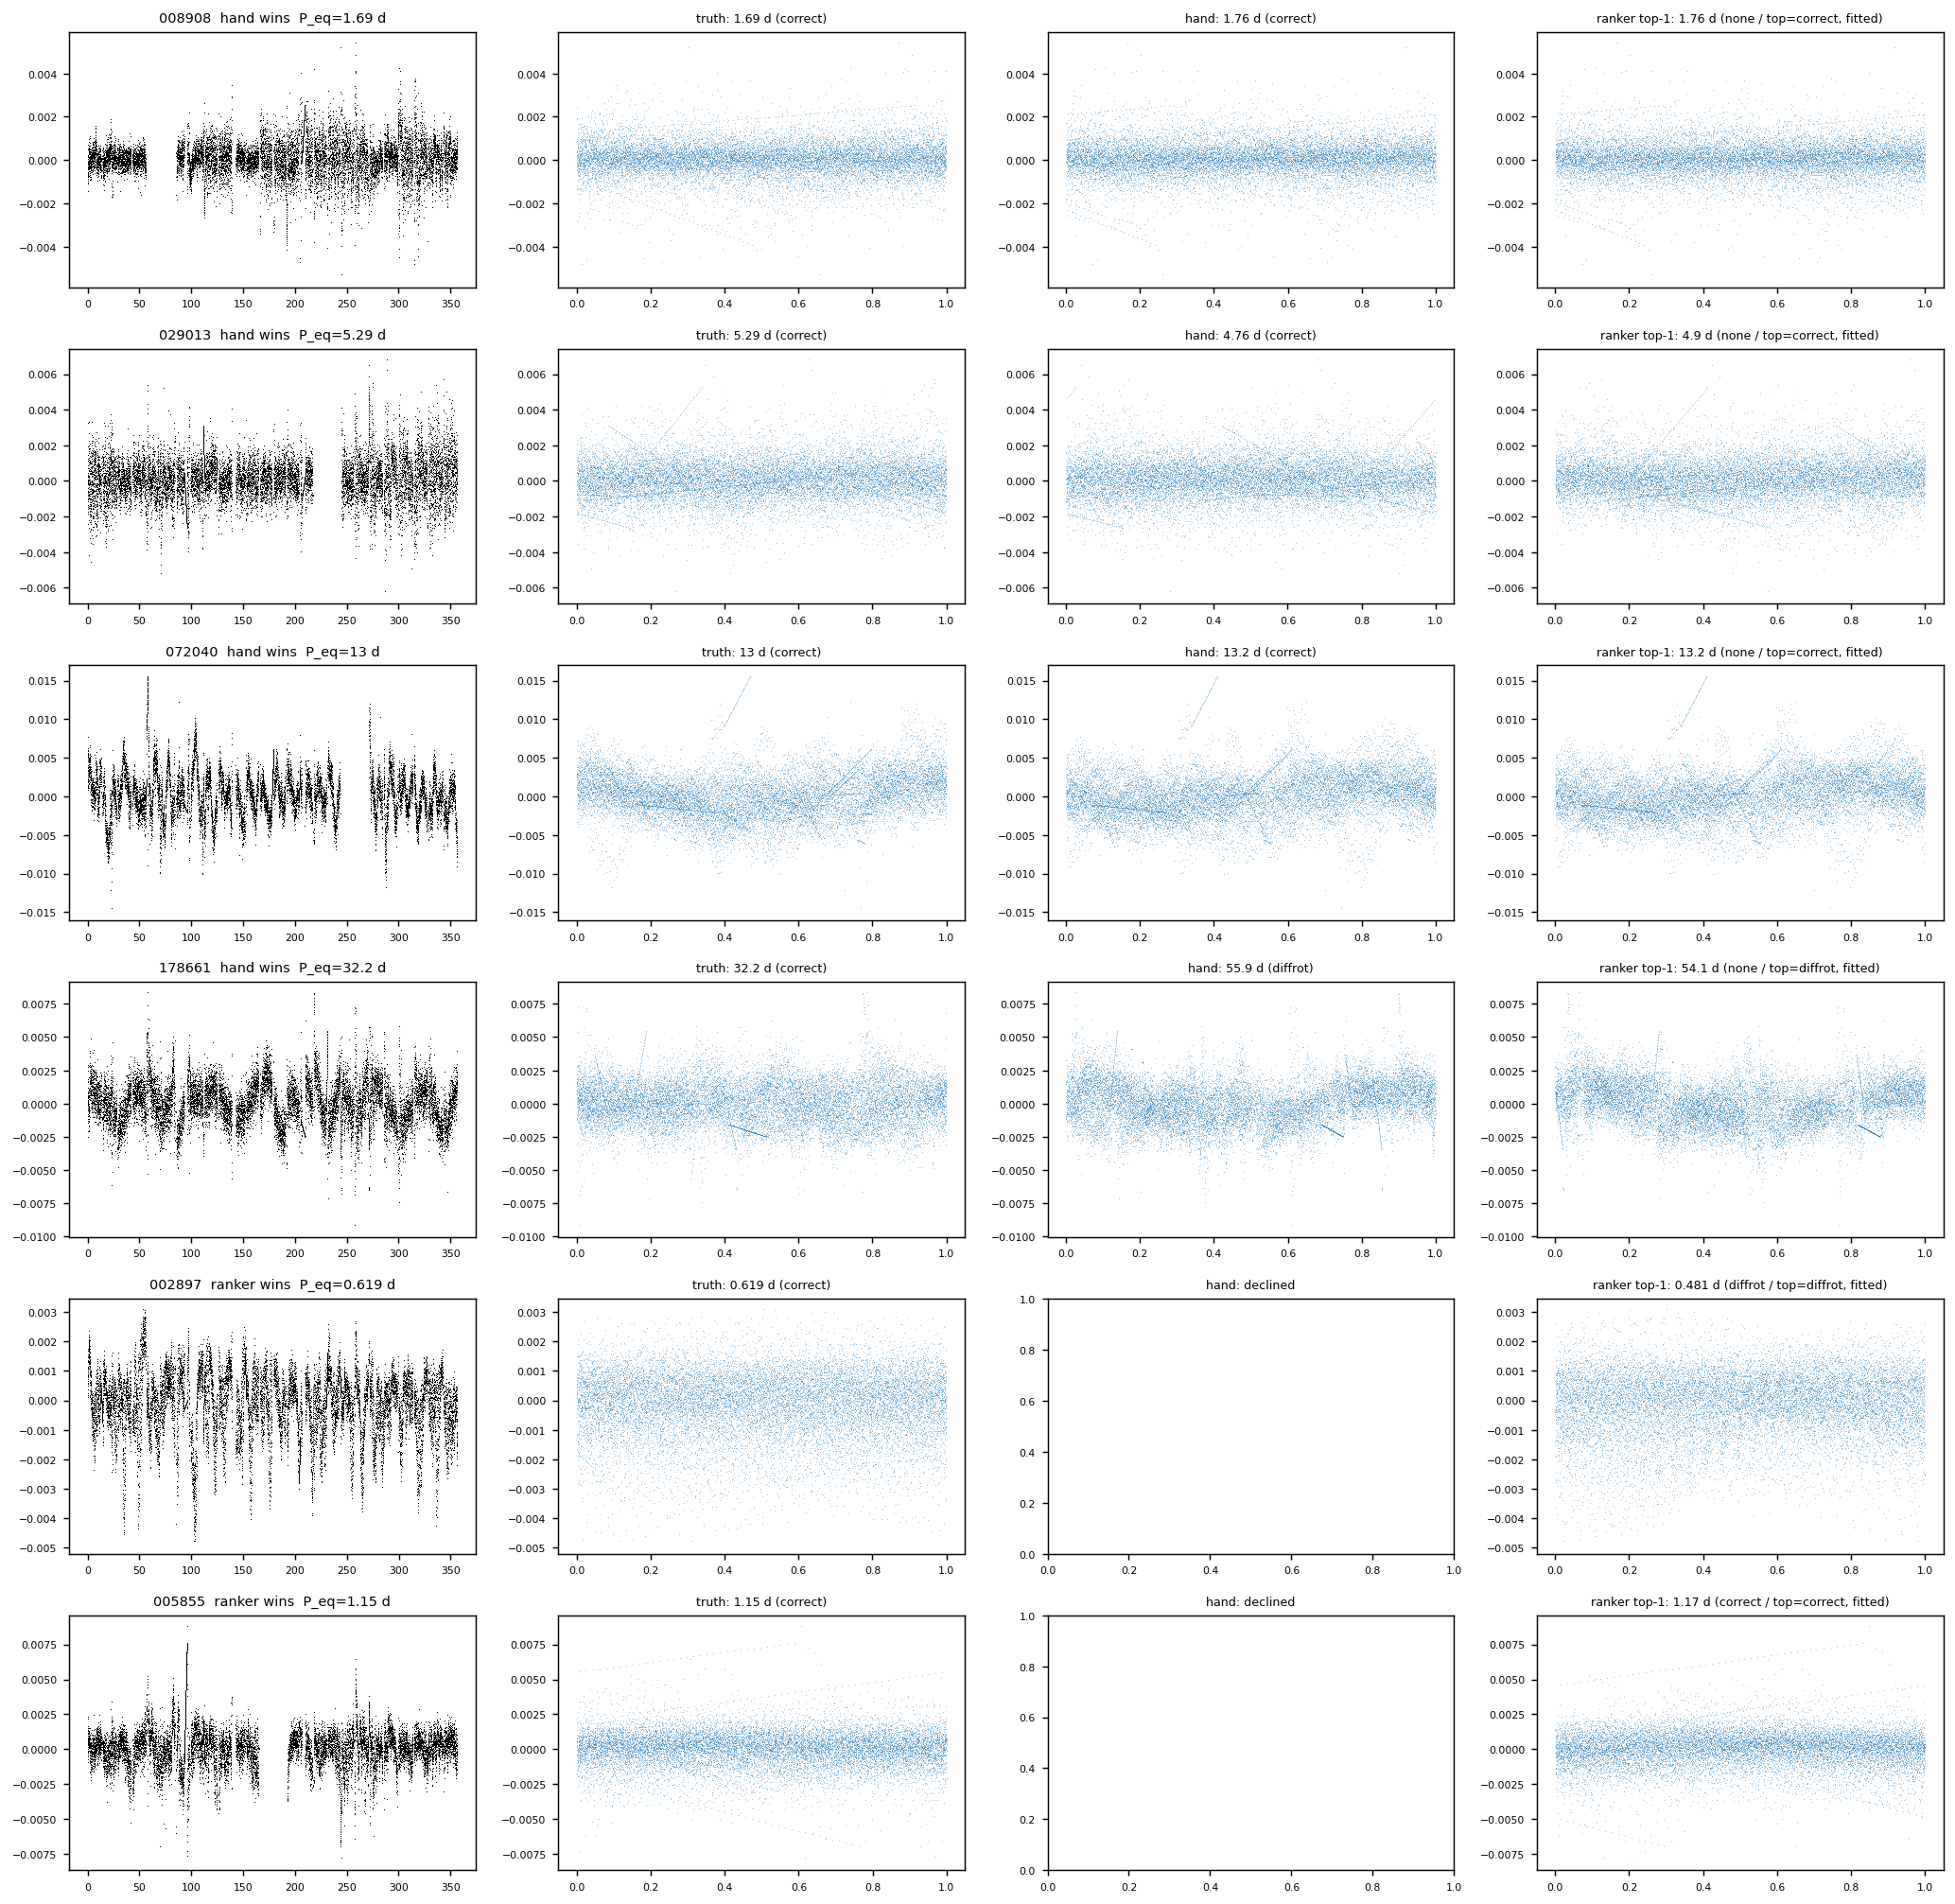

,star_id,case,true_period,period_lo,period_hi,hand_period,hand_outcome,ranker_period,ranker_outcome,top_outcome,top_kind,why,hand_choice_rank
0,smarts-tess-v1.0-008908,hand wins,1.6922,1.719927,1.963175,1.757788,correct,1.757788,none,correct,fitted,declined (top was right),1.0
1,smarts-tess-v1.0-029013,hand wins,5.2881,4.632900,5.061751,4.760573,correct,4.899307,none,correct,fitted,declined (top was right),2.0
2,smarts-tess-v1.0-072040,hand wins,13.0046,12.554216,12.941490,13.181507,correct,13.181507,none,correct,fitted,declined (top was right),1.0
3,smarts-tess-v1.0-178661,hand wins,32.1968,43.429086,101.499290,55.925273,diffrot,54.066004,none,diffrot,fitted,declined (top was right),2.0
4,smarts-tess-v1.0-002897,ranker wins,0.6187,0.401659,0.520791,NaN,none,0.480862,diffrot,diffrot,fitted,NaN,NaN
5,smarts-tess-v1.0-005855,ranker wins,1.1475,1.185757,1.284362,NaN,none,1.172112,correct,correct,fitted,NaN,NaN


In [13]:
display(Image('figures/fig_examples.png'))
pd.read_csv('data/examples.csv')

## Diffrot / half-lag bias

In [14]:
display(pd.read_csv('data/diffrot_bias.csv').round(3))
imp = pd.read_csv('data/importance.csv')
imp[imp.feature.str.contains('half_lag')][['feature','mean_abs_shap','mean_shap_rel2','mean_shap_rel1','mean_shap_rel0']].round(4)

,set,stars,n,answered,success,hand_success,median_top_score
0,assigned,has correct cand (max rel 2),513,0.419,0.329,0.265,0.901
1,assigned,diffrot-only (max rel 1),88,0.273,0.216,0.136,0.460
2,assigned,top is correct,230,0.596,0.596,0.478,1.881
3,assigned,top is diffrot,98,0.520,0.520,0.378,1.654
4,fullyear,has correct cand (max rel 2),649,0.436,0.368,0.348,1.027
5,fullyear,diffrot-only (max rel 1),115,0.348,0.243,0.191,0.576
6,fullyear,top is correct,317,0.653,0.653,0.621,2.082
7,fullyear,top is diffrot,124,0.484,0.484,0.371,1.269
8,train_oof,has correct cand (max rel 2),508,0.423,0.398,0.317,0.954
9,train_oof,diffrot-only (max rel 1),93,0.269,0.269,0.183,0.448


,feature,mean_abs_shap,mean_shap_rel2,mean_shap_rel1,mean_shap_rel0
48,acf_half_lag_contrast,0.1688,0.1615,0.0468,-0.1124
130,gate_half_lag_consistency_value,0.0474,0.0134,-0.0013,-0.0187
131,gate_half_lag_consistency_pass,0.0065,0.0060,0.0010,-0.0040
